In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()

Saving Student_Performance.csv to Student_Performance.csv


In [ ]:
df1 = pd.read_csv("../../data/Student_Performance.csv")
df1

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
...,...,...,...,...,...,...
9995,1,49,Yes,4,2,23.0
9996,7,64,Yes,8,5,58.0
9997,6,83,Yes,8,5,74.0
9998,9,97,Yes,7,0,95.0


In [ ]:
df1 = pd.get_dummies(
    df1,
    columns=['Extracurricular Activities'],
    dtype=int
)

df1.head()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index,Extracurricular Activities_No,Extracurricular Activities_Yes
0,7,99,9,1,91.0,0,1
1,4,82,4,2,65.0,1,0
2,8,51,7,2,45.0,0,1
3,5,52,5,2,36.0,0,1
4,7,75,8,5,66.0,1,0


In [ ]:
X = df1.drop('Performance Index', axis=1)
y = df1['Performance Index']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
from sklearn.metrics import r2_score

y_train_pred = linear_model.predict(X_train)
y_test_pred = linear_model.predict(X_test)

print("Training R²:", r2_score(y_train, y_train_pred))
print("Testing R²:", r2_score(y_test, y_test_pred))

Training R²: 0.9886898790682355
Testing R²: 0.9889832909573145


In [ ]:
X_demo = 6 * np.random.rand(100,1) - 3

In [ ]:
y_demo = (
    0.6 * X_demo**2
    + 0.5 * X_demo
    + 5
    + np.random.randn(100, 1)
)

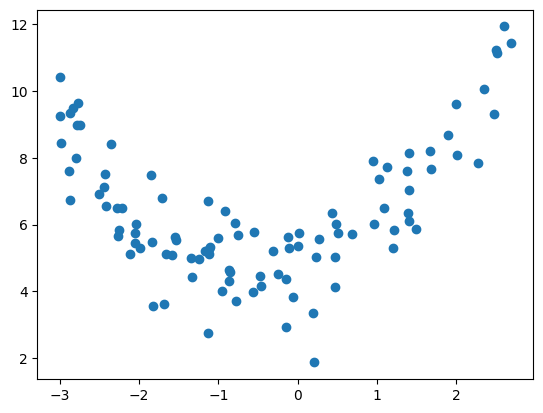

In [ ]:
plt.scatter(X_demo, y_demo)

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
poly = PolynomialFeatures(
    degree=10,
    include_bias=False
)

In [ ]:
X_example = np.array([[2],
                      [3],
                      [4]])

In [ ]:
poly.fit_transform(X_example)

array([[2.000000e+00, 4.000000e+00, 8.000000e+00, 1.600000e+01,
        3.200000e+01, 6.400000e+01, 1.280000e+02, 2.560000e+02,
        5.120000e+02, 1.024000e+03],
       [3.000000e+00, 9.000000e+00, 2.700000e+01, 8.100000e+01,
        2.430000e+02, 7.290000e+02, 2.187000e+03, 6.561000e+03,
        1.968300e+04, 5.904900e+04],
       [4.000000e+00, 1.600000e+01, 6.400000e+01, 2.560000e+02,
        1.024000e+03, 4.096000e+03, 1.638400e+04, 6.553600e+04,
        2.621440e+05, 1.048576e+06]])

In [ ]:
X_demo_poly = poly.fit_transform(X_demo)

In [ ]:
X_demo_poly[:5]

array([[ 1.90084406e+00,  3.61320815e+00,  6.86814525e+00,
         1.30552731e+01,  2.48160383e+01,  4.71714191e+01,
         8.96655119e+01,  1.70440156e+02,  3.23980158e+02,
         6.15835759e+02],
       [-1.54528288e+00,  2.38789917e+00, -3.68997970e+00,
         5.70206244e+00, -8.81129946e+00,  1.36159502e+01,
        -2.10404947e+01,  3.25135161e+01, -5.02425797e+01,
         7.76389982e+01],
       [-5.63885452e-01,  3.17966802e-01, -1.79296854e-01,
         1.01102887e-01, -5.70104473e-02,  3.21473618e-02,
        -1.81274296e-02,  1.02217939e-02, -5.76392084e-03,
         3.25019111e-03],
       [-2.21856030e+00,  4.92200980e+00, -1.09197755e+01,
         2.42261805e+01, -5.37472423e+01,  1.19241498e+02,
        -2.64544453e+02,  5.86907821e+02, -1.30209039e+03,
         2.88876605e+03],
       [-2.51144205e+00,  6.30734116e+00, -1.58405218e+01,
         3.97825525e+01, -9.99115750e+01,  2.50922130e+02,
        -6.30176389e+02,  1.58265148e+03, -3.97473747e+03,
         9.

In [ ]:
poly_model = LinearRegression()

In [ ]:
poly_model.fit(X_demo_poly, y_demo)

LinearRegression()

In [ ]:
X_new = np.linspace(-3, 3, 200).reshape(-1, 1)

X_new_poly = poly.transform(X_new)
y_new = poly_model.predict(X_new_poly)

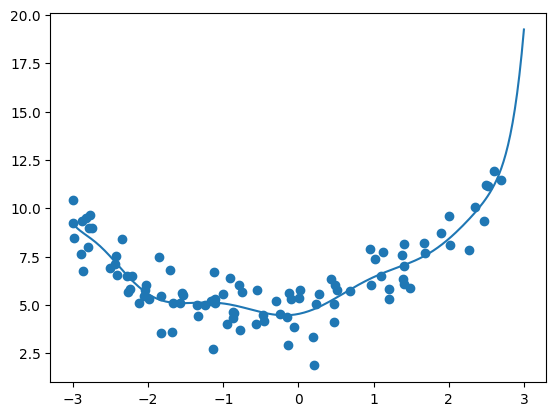

In [ ]:
plt.scatter(X_demo, y_demo)

plt.plot(X_new, y_new)

In [ ]:
X_train_demo, X_test_demo, y_train_demo, y_test_demo = train_test_split(
    X_demo,
    y_demo,
    test_size=0.3,
    random_state=42
)

In [ ]:
for degree in [1, 2, 5, 10, 20]:

    poly = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )

    X_train_poly = poly.fit_transform(X_train_demo)
    X_test_poly = poly.transform(X_test_demo)

    model = LinearRegression()

    model.fit(X_train_poly, y_train_demo)

    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    train_r2 = r2_score(y_train_demo, train_pred)
    test_r2 = r2_score(y_test_demo, test_pred)

    print(
        "Degree:", degree,
        "Training R²:", round(train_r2, 3),
        "Testing R²:", round(test_r2, 3)
        )

Degree: 1 Training R²: 0.01 Testing R²: 0.067
Degree: 2 Training R²: 0.737 Testing R²: 0.817
Degree: 5 Training R²: 0.751 Testing R²: 0.797
Degree: 10 Training R²: 0.802 Testing R²: 0.609
Degree: 20 Training R²: 0.825 Testing R²: 0.685
